# Aciklanabilir Yapay Zeka (XAI) — Grad-CAM Analizi

Bu notebook, egitilen U-Net ve DeepLabV3+ segmentasyon modellerinin tahminlerini farkli CAM (Class Activation Mapping) yontemleriyle gorsellestirerek "model neye bakarak karar veriyor" sorusuna cevap arar. Endustriyel kalite kontrol gibi kritik uygulamalarda, modelin dogru sebeplerden dogru tahmin yapip yapmadigini dogrulamak guven acisindan onemlidir — sadece "Dice skoru yuksek" demek yeterli degildir.

Icerik:
1. Ayni goruntu uzerinde uc farkli CAM yontemini (GradCAM, GradCAM++, EigenCAM) karsilastirma
2. U-Net ile DeepLabV3+'in dikkat haritalarini yan yana karsilastirma
3. En dusuk Dice skorlu (basarisiz) orneklerin XAI ile incelenmesi

Bu notebook, `src/visualize.py` icindeki tek-CAM/statik-PNG pipeline'ini tamamlayan, kesif amacli/interaktif bir analizdir.

In [1]:
import sys
from pathlib import Path

import numpy as np
import torch
import yaml
import matplotlib.pyplot as plt

sys.path.append(str(Path("..") / "src"))

from augmentations import get_val_transform
from dataset import MVTecSegDataset
from models.factory import build_model
from visualize import denormalize, mask_to_color, per_sample_dice

from pytorch_grad_cam import GradCAM, GradCAMPlusPlus, EigenCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import SemanticSegmentationTarget

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

## Modelleri ve test verisini yukle

In [2]:
PROJECT_ROOT = Path("..")


def load_model(config_path):
    with open(PROJECT_ROOT / config_path, encoding="utf-8") as f:
        config = yaml.safe_load(f)
    run_name = config["model"]["name"]
    model = build_model(
        config["model"]["name"], config["model"]["encoder"], config["model"]["encoder_weights"]
    ).to(device)
    checkpoint = PROJECT_ROOT / config["logging"]["checkpoint_dir"] / f"{run_name}_best.pt"
    model.load_state_dict(torch.load(checkpoint, map_location=device))
    model.eval()
    return model, config


unet_model, unet_config = load_model("configs/unet_baseline.yaml")
deeplab_model, deeplab_config = load_model("configs/deeplabv3plus.yaml")

image_size = unet_config["data"]["image_size"]
manifest_path = PROJECT_ROOT / "data" / "processed" / "splits.csv"
test_ds = MVTecSegDataset(manifest_path, "test", transform=get_val_transform(image_size))
print(f"Modeller yuklendi. Test seti: {len(test_ds)} goruntu.")

C:\Users\ibrahim\AppData\Local\Temp\ipykernel_16064\3262243569.py:12: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(checkpoint, map_location

Modeller yuklendi. Test seti: 23 goruntu.


In [3]:
def predict(model, image_t):
    input_tensor = image_t.unsqueeze(0).to(device)
    with torch.no_grad():
        logits = model(input_tensor)
        pred_mask = (torch.sigmoid(logits) > 0.5).float()[0, 0].cpu().numpy()
    return input_tensor, pred_mask


def compute_cam(model, cam_cls, input_tensor, pred_mask):
    target_layers = [model.encoder.layer4[-1]]
    targets = [SemanticSegmentationTarget(0, pred_mask)]
    with cam_cls(model=model, target_layers=target_layers) as cam:
        grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]
    return grayscale_cam


def overlay_mask(rgb_img, mask, color):
    blended = rgb_img * 0.6 + mask_to_color(mask, color) * 0.4
    return np.clip(blended, 0, 1)

## 1. CAM yontemlerinin karsilastirilmasi (U-Net)

`GradCAM`, gradyanlarin agirlikli ortalamasini kullanir. `GradCAM++`, ozellikle ayni sinifin birden fazla/karmasik bolgesi oldugunda daha keskin lokalizasyon hedefler. `EigenCAM` ise gradyan kullanmadan, aktivasyonlarin en buyuk temel bilesenini (PCA) alir — daha hizli ama sinifa daha az duyarlidir. Ucunu ayni goruntude karsilastirmak, hangi yontemin bu problem icin daha anlamli oldugunu gosterir.

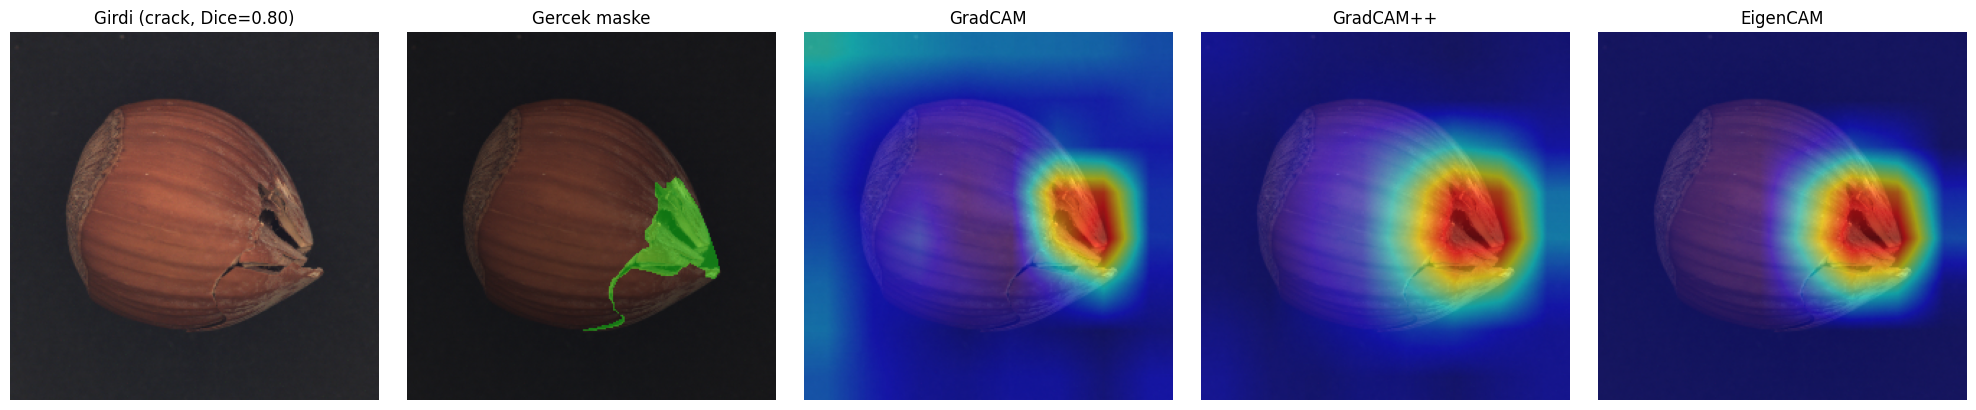

In [4]:
idx = 1  # crack ornegi
image_t, mask_t, category = test_ds[idx]
input_tensor, pred_mask = predict(unet_model, image_t)
gt_mask = mask_t[0].numpy()
rgb_img = denormalize(image_t)
dice_score = per_sample_dice(pred_mask, gt_mask)

cam_classes = {"GradCAM": GradCAM, "GradCAM++": GradCAMPlusPlus, "EigenCAM": EigenCAM}
cam_images = {
    name: show_cam_on_image(rgb_img, compute_cam(unet_model, cls, input_tensor, pred_mask), use_rgb=True)
    for name, cls in cam_classes.items()
}

fig, axes = plt.subplots(1, 2 + len(cam_images), figsize=(4 * (2 + len(cam_images)), 4))
axes[0].imshow(rgb_img)
axes[0].set_title(f"Girdi ({category}, Dice={dice_score:.2f})")
axes[0].axis("off")
axes[1].imshow(overlay_mask(rgb_img, gt_mask, (0, 1, 0)))
axes[1].set_title("Gercek maske")
axes[1].axis("off")
for ax, (name, im) in zip(axes[2:], cam_images.items()):
    ax.imshow(im)
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. U-Net vs DeepLabV3+ dikkat haritalari

Ayni goruntu icin iki farkli mimarinin Grad-CAM haritalari karsilastirilir — iki model de ayni bolgeye mi odaklaniyor, yoksa farkli ipuclari mi kullaniyor?

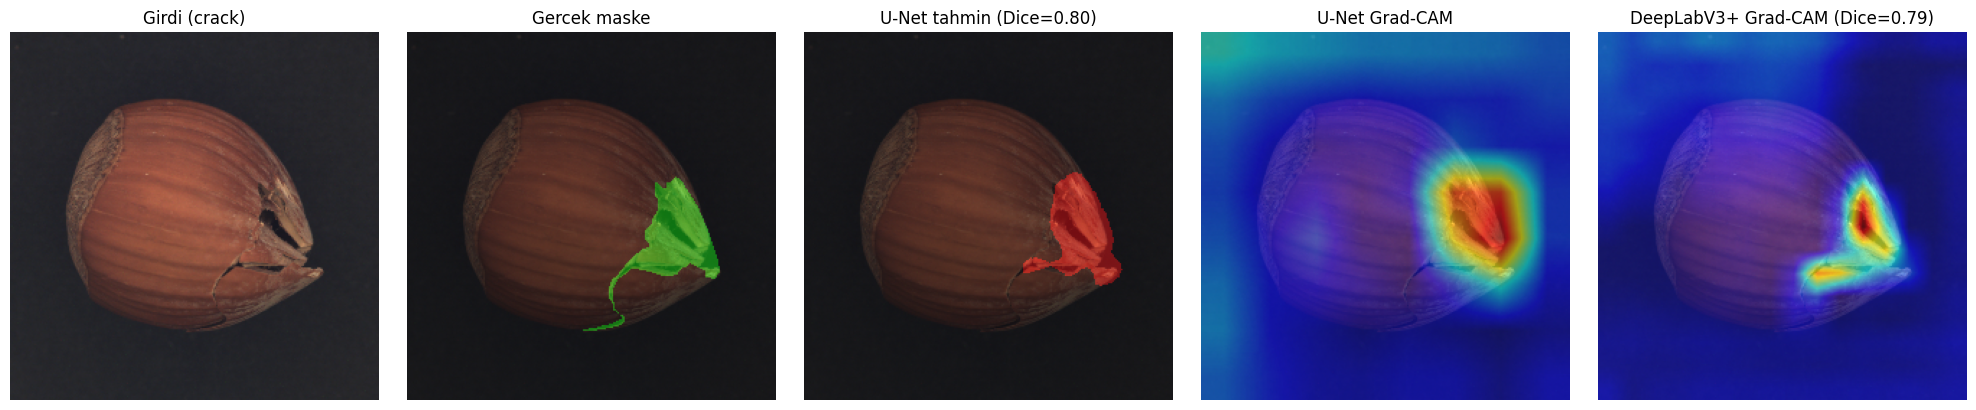

In [5]:
unet_input, unet_pred = predict(unet_model, image_t)
deeplab_input, deeplab_pred = predict(deeplab_model, image_t)

unet_dice = per_sample_dice(unet_pred, gt_mask)
deeplab_dice = per_sample_dice(deeplab_pred, gt_mask)

unet_cam = show_cam_on_image(rgb_img, compute_cam(unet_model, GradCAM, unet_input, unet_pred), use_rgb=True)
deeplab_cam = show_cam_on_image(rgb_img, compute_cam(deeplab_model, GradCAM, deeplab_input, deeplab_pred), use_rgb=True)

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
axes[0].imshow(rgb_img); axes[0].set_title(f"Girdi ({category})"); axes[0].axis("off")
axes[1].imshow(overlay_mask(rgb_img, gt_mask, (0, 1, 0))); axes[1].set_title("Gercek maske"); axes[1].axis("off")
axes[2].imshow(overlay_mask(rgb_img, unet_pred, (1, 0, 0))); axes[2].set_title(f"U-Net tahmin (Dice={unet_dice:.2f})"); axes[2].axis("off")
axes[3].imshow(unet_cam); axes[3].set_title("U-Net Grad-CAM"); axes[3].axis("off")
axes[4].imshow(deeplab_cam); axes[4].set_title(f"DeepLabV3+ Grad-CAM (Dice={deeplab_dice:.2f})"); axes[4].axis("off")
plt.tight_layout()
plt.show()

## 3. Basarisiz orneklerin XAI ile incelenmesi

U-Net icin tum test setinde Dice skoru hesaplanir, en dusuk skorlu 3 ornek Grad-CAM ile birlikte incelenir. Amac: model dusuk skor verdiginde, dikkatinin dogru bolgeye gidip gitmedigini gormek (lokalizasyon hatasi mi, yoksa dogru bolgeye bakip yanlis sinir mi ciziyor).

En dusuk Dice skorlu ornekler: [(0, 0.3660522997379303, 'crack'), (3, 0.6172695159912109, 'cut'), (2, 0.6706143617630005, 'cut')]


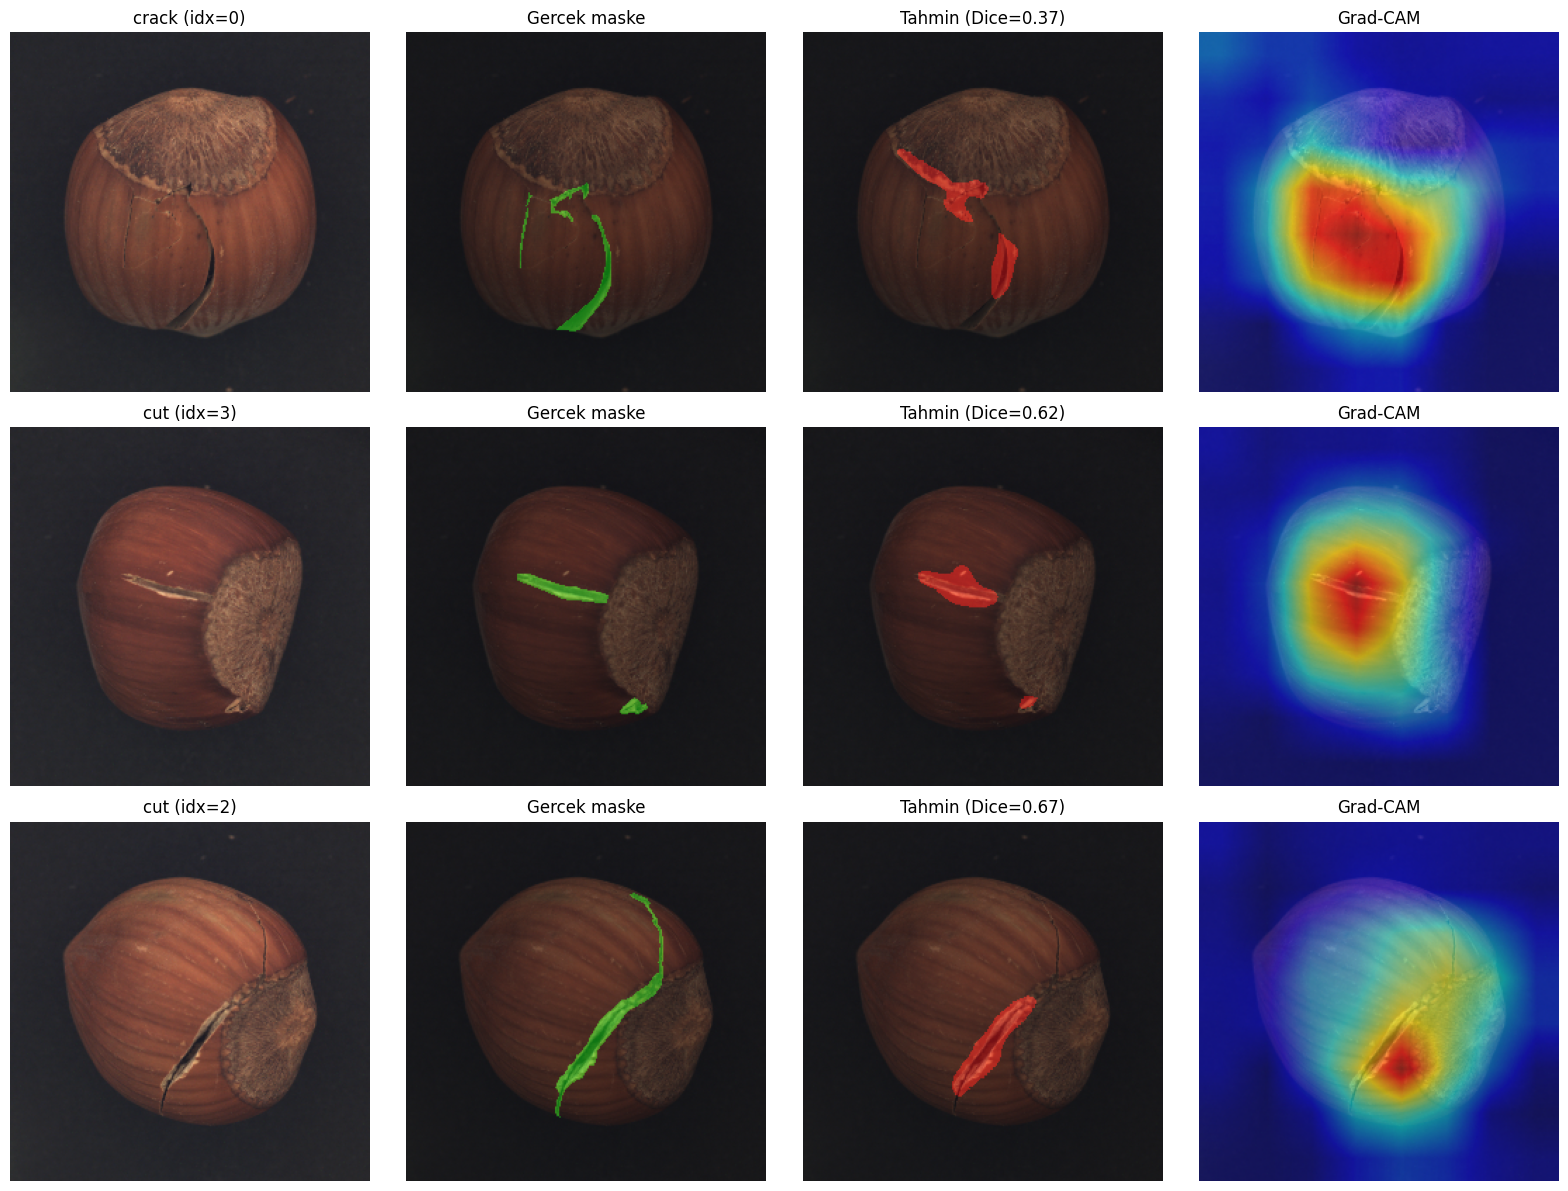

In [6]:
scored = []
for i in range(len(test_ds)):
    img_t, msk_t, cat = test_ds[i]
    inp, pred = predict(unet_model, img_t)
    dice = per_sample_dice(pred, msk_t[0].numpy())
    scored.append((i, dice, cat))
scored.sort(key=lambda x: x[1])
worst = scored[:3]
print("En dusuk Dice skorlu ornekler:", worst)

fig, axes = plt.subplots(len(worst), 4, figsize=(16, 4 * len(worst)))
for row, (i, dice, cat) in enumerate(worst):
    img_t, msk_t, _ = test_ds[i]
    inp, pred = predict(unet_model, img_t)
    gt = msk_t[0].numpy()
    rgb = denormalize(img_t)
    cam_img = show_cam_on_image(rgb, compute_cam(unet_model, GradCAM, inp, pred), use_rgb=True)

    axes[row, 0].imshow(rgb); axes[row, 0].set_title(f"{cat} (idx={i})"); axes[row, 0].axis("off")
    axes[row, 1].imshow(overlay_mask(rgb, gt, (0, 1, 0))); axes[row, 1].set_title("Gercek maske"); axes[row, 1].axis("off")
    axes[row, 2].imshow(overlay_mask(rgb, pred, (1, 0, 0))); axes[row, 2].set_title(f"Tahmin (Dice={dice:.2f})"); axes[row, 2].axis("off")
    axes[row, 3].imshow(cam_img); axes[row, 3].set_title("Grad-CAM"); axes[row, 3].axis("off")
plt.tight_layout()
plt.show()

## Bulgular

- Grad-CAM, GradCAM++ ve EigenCAM ayni encoder katmanindan (`layer4`, 8x8 cozunurluk) turetildigi icin ucu de genis/bulanik isi haritalari uretiyor; `crack`/`cut` gibi ince kusurlarin tam sinirini degil, kusurun bulundugu genel bolgeyi isaret ediyorlar. Bu, tahmin maskesinin kendisinin (pikselsel) Grad-CAM'den cok daha hassas oldugunu, CAM'in sadece "nereye bakti" sorusuna kaba bir cevap verdigini gosteriyor.
- U-Net ve DeepLabV3+'in dikkat bolgeleri buyuk olcude ortusuyor — iki mimari de ayni gorsel ipuclarina (kusurun bulundugu bolgedeki doku/kontrast degisimi) yoneliyor; bu, dusuk test-set farklarinin (bkz. README) mimari secimden degil ayni temel ozelliklere dayanmalarindan kaynaklanabilecegini destekliyor.
- En dusuk Dice skorlu orneklerde (`crack`, `cut`) Grad-CAM genelde kusurun civarina dogru odaklaniyor (tamamen kacirmiyor) ama tahmin maskesi kusurun ince/dusuk kontrastli kismini eksik yakaliyor — yani hata, "yanlis yere bakma"dan degil, "dogru yere bakip sinirini kacirma"dan kaynaklaniyor. Bu, gelecekte daha sig/yuksek cozunurluklu bir katmandan (orn. `layer2`) alinacak CAM'in veya `LayerCAM` gibi coklu-olcekli yontemlerin daha faydali olabilecegine isaret ediyor.